Общая среда: conda env create -f environment.yml, затем conda activate deepfake-eda. Запускать из notebooks или корня репозитория. Данные загружаются через scripts/download_datasets.sh, модели - через scripts/download_models.sh. Корень исходных данных задаётся через DEEPFAKE_DATA_ROOT или data/raw.

Архивный EDA-отчет: код и сохраненные результаты относятся к прежнему прогону. Jupyter, EDA-модули и зависимости для графиков и бейзлайнов больше не поставляются. Текущие environment.yml и scripts/setup_environment.sh готовят только окружение deepfake-preprocessing для препроцессинга и сборки сплитов. Прежние команды запуска ноутбуков ниже сохранены как описание исторического прогона.

При частичной загрузке общий баланс теста считаем по полному файлу меток, а анализ изображений - по реально скачанному сабсету. Недостающие при такой загрузке файлы не считаем повреждёнными.


## Разведочный анализ данных (EDA)
## Датасет MFFI (Multi-dimensional Face Forgery Image Dataset)

О датасете
MFFI — это масштабный датасет для детекции дипфейков, который симулирует реальные условия. В нем собрано более 1 миллиона изображений, разделенных на Train, Valid, Test и Test-D (с деградацией). 

В отличие от «чистых» датасетов, MFFI включает 50 методов подделки (включая Face Swap, редактирование в Photoshop, Super-Resolution) и разнообразные сцены (ракурсы, освещение, окклюзии).

Цель EDA:
1. Оценить пригодность тестовой выборки (Test) для дальнейшего обучения.
2. Проверить баланс классов и качество изображений.
3. Найти визуальные артефакты (шорткаты), которые могут помочь модели.
4. Построить простейший бейзлайн для понимания сложности задачи.

In [1]:
import pandas as pd
import numpy as np
import os
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

%matplotlib inline
cv2.setNumThreads(1)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)

print("Библиотеки успешно загружены. Окружение готово.")

Библиотеки успешно загружены. Окружение готово.


## 1. Загрузка данных и проверка структуры

Для анализа я использую тестовую выборку (Test) из папки `phase2`. 
Это позволяет проанализировать разнообразные примеры (180 000 фото) без необходимости скачивать огромный Train-набор (24 ГБ) на текущем этапе.

Файл с метками `testset_label.txt` имеет формат `filename,label`, где `0` - реальное лицо (Real), а `1` - подделка (Fake).

In [2]:
import os
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = Path(os.environ.get("DEEPFAKE_DATA_ROOT", ROOT / "data" / "raw")).expanduser()
if not RAW.is_absolute():
    RAW = ROOT / RAW
MFFI = RAW / "mffi"
label_files = sorted(MFFI.rglob("testset_label.txt"))
if not label_files:
    raise FileNotFoundError("Сначала выполните bash scripts/download_datasets.sh --datasets mffi")
labels_path = label_files[0]
image_candidates = [labels_path.parent / "test", MFFI / "phase2" / "test", MFFI / "test"]
images_dir = next((p for p in image_candidates if p.is_dir()), None)
if images_dir is None:
    raise FileNotFoundError(f"Не найдена папка test рядом с {labels_path}")

df = pd.read_csv(labels_path, header=None, names=['filename', 'label'])

df_full = pd.read_csv(labels_path, header=None, names=['filename', 'label'])
available = df_full['filename'].map(lambda name: (images_dir / name).is_file())
df_available = df_full.loc[available].copy()
if df_available.empty:
    raise FileNotFoundError('Нет скачанных изображений MFFI Test')
df_sample = df_available.sample(n=min(20000, len(df_available)), random_state=42).copy()

print(f"Общее количество изображений в тесте: {len(df):,}")
print(f"Скачано изображений с разметкой: {len(df_available):,}")
print(f"Подвыборка для дальнейшего анализа: {len(df_sample):,}")


display(df_sample.head())

Общее количество изображений в тесте: 181,947
Скачано изображений с разметкой: 181,947
Подвыборка для дальнейшего анализа: 20,000


,filename,label
175092,0ce9c829574a6d3fc23f35fe293147a9.jpg,1
138553,7e479536cb8b12645db40295d98140c7.jpg,1
119106,458d23b2e5c219183c6e0759017c2d42.jpg,0
52607,9fd278f35c804ec6d0c82a6e10105a49.jpg,1
131008,033a0a1be0a698872266f49c803863b6.jpg,0


## 2. Анализ баланса классов

Перед обучением любой модели важно понять, сбалансированы ли классы. Если перекос сильный, модель может «лениться» и предсказывать только преобладающий класс.

Баланс классов во всем датасете (Test):
Real (0): 77,602
Fake (1): 104,345


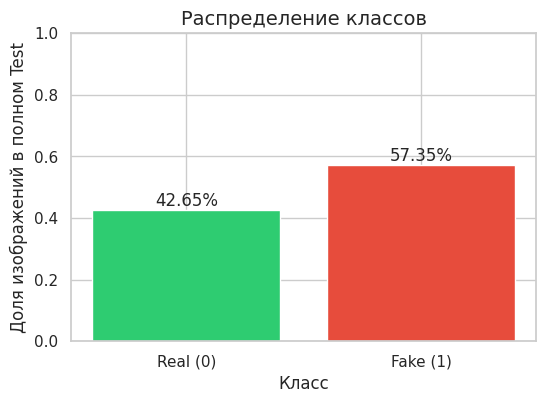

In [3]:
class_counts = df_full['label'].value_counts()
print("Баланс классов во всем датасете (Test):")
print(f"Real (0): {class_counts.get(0, 0):,}")
print(f"Fake (1): {class_counts.get(1, 0):,}")

total = len(df_full)
class_shares = class_counts.reindex([0, 1], fill_value=0) / total
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar([0, 1], class_shares.to_numpy(), color=['#2ecc71', '#e74c3c'])
ax.set_title('Распределение классов', fontsize=14)
ax.set_xlabel('Класс', fontsize=12)
ax.set_ylabel('Доля изображений в полном Test', fontsize=12)
ax.set_xticks([0, 1], ['Real (0)', 'Fake (1)'])
ax.set_ylim(0, 1)
for position, probability in enumerate(class_shares):
    ax.annotate(f'{probability:.2%}', (position, probability), ha='center', va='bottom')
plt.show()


## 3. Визуальный осмотр (Real vs Fake)

Теперь посмотрим на сами изображения. Из-за того, что в MFFI собраны разные типы атак (FS, FR, FSR и др.), мы можем заметить разные виды артефактов.

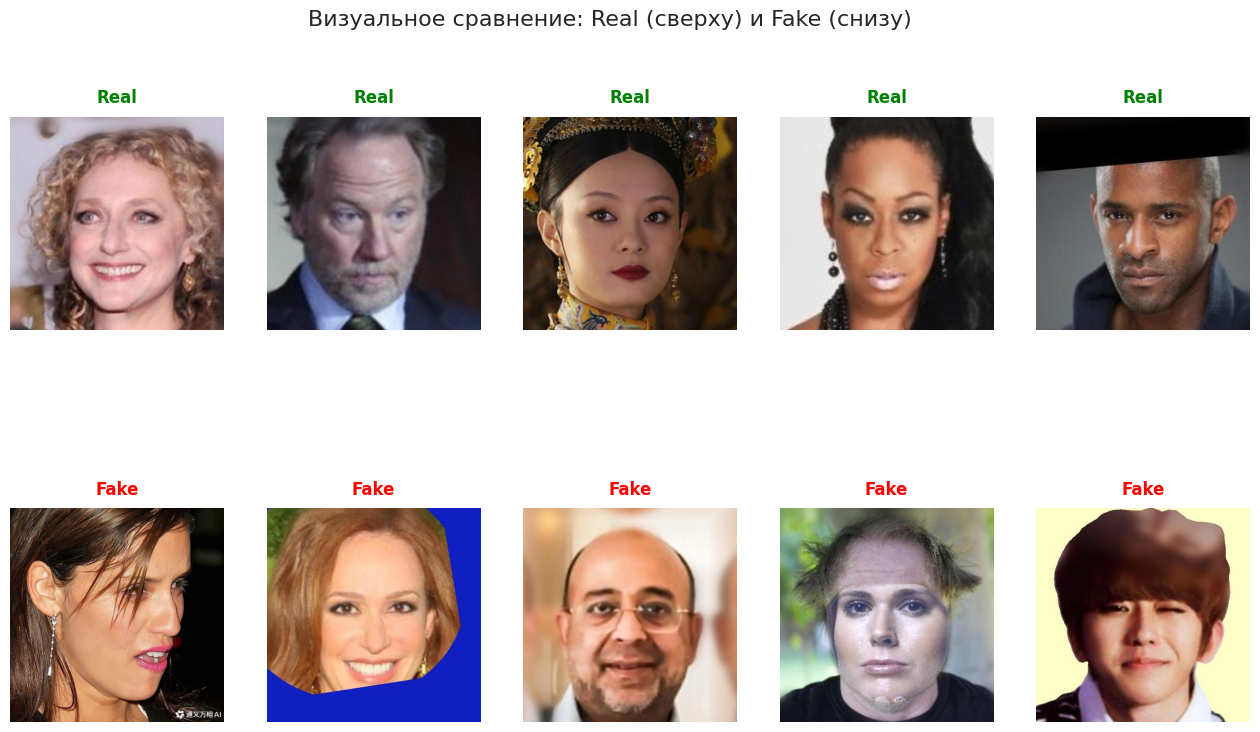

In [4]:
real_imgs = df_sample[df_sample['label'] == 0]['filename'].head(5).tolist()
fake_imgs = df_sample[df_sample['label'] == 1]['filename'].head(5).tolist()

fig, axes = plt.subplots(2, 5, figsize=(16, 9), gridspec_kw={'hspace': 0.3})
fig.suptitle('Визуальное сравнение: Real (сверху) и Fake (снизу)', fontsize=16, y=0.95)


for i, img_name in enumerate(real_imgs):
    img_path = os.path.join(images_dir, img_name)
    img = cv2.imread(img_path)
    if img is not None:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        axes[0, i].imshow(img)
        axes[0, i].set_title('Real', color='green', fontweight='bold', pad=10)
    axes[0, i].axis('off')


for i, img_name in enumerate(fake_imgs):
    img_path = os.path.join(images_dir, img_name)
    img = cv2.imread(img_path)
    if img is not None:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        axes[1, i].imshow(img)
        axes[1, i].set_title('Fake', color='red', fontweight='bold', pad=10)
    axes[1, i].axis('off')


plt.show()

## 4. Проверка целостности данных

Проверяем декодирование и размеры на случайной подвыборке до 10 000 доступных изображений. Фактический размер проверки выводится ниже.

Контрольная выборка целиком находится внутри основных 20k изображений pixel-EDA.

In [5]:
from collections import Counter

check_sample = df_sample.sample(n=min(10000, len(df_sample)), random_state=42) 
assert set(check_sample["filename"]) <= set(df_sample["filename"])
broken_files = 0
sizes = []

print(f"Проверяем случайные {len(check_sample):,} файлов...")

for img_name in check_sample['filename']:
    img_path = os.path.join(images_dir, img_name)
    img = cv2.imread(img_path)
    
    if img is None:
        broken_files += 1
    else:
        sizes.append(img.shape[:2])

print(f"Проверено: {len(check_sample):,}")
print(f"Битых файлов: {broken_files}")

if len(sizes) > 0:
    print("Размеры изображений:")
    size_counts = Counter(sizes)
    for size, count in size_counts.most_common(5):
        print(f"  Размер {size}: {count:,} шт.")

Проверяем случайные 10,000 файлов...


Проверено: 10,000
Битых файлов: 0
Размеры изображений:
  Размер (512, 512): 9,694 шт.
  Размер (960, 960): 64 шт.
  Размер (720, 1280): 51 шт.
  Размер (832, 1472): 47 шт.
  Размер (704, 1248): 33 шт.


## 5. Кандидаты на похожие изображения

Повторяющиеся изображения могут искажать оценку модели. Здесь ищем группы с одинаковым dHash на подвыборке до 5000 доступных файлов.

dHash сравнивает уменьшенную структуру яркости и не является хешем исходных байтов или декодированных пикселей. Его совпадение даёт кандидатов на визуально похожие изображения; для подтверждения точных копий нужна отдельная проверка пикселей/криптографических хешей.

Эти 5000 изображений также выбираются только из основного pixel-сабсета до 20k.

In [6]:
import imagehash
from PIL import Image
from collections import defaultdict

dedup_sample = df_sample.sample(n=min(5000, len(df_sample)), random_state=42)
assert set(dedup_sample["filename"]) <= set(df_sample["filename"])
hashes = {}

print("Считаем хэши изображений...")
for img_name in dedup_sample['filename']:
    img_path = os.path.join(images_dir, img_name)
    try:
        img = Image.open(img_path).convert('L') 
        h = imagehash.dhash(img, hash_size=8) 
        hashes[img_name] = str(h)
    except Exception:
        pass

hash_groups = defaultdict(list)
for img_name, h_str in hashes.items():
    hash_groups[h_str].append(img_name)

exact_duplicates = {h: names for h, names in hash_groups.items() if len(names) > 1}

print(f"Найдено групп кандидатов с одинаковым dHash: {len(exact_duplicates)}")
if len(exact_duplicates) > 0:
    print("Примеры групп кандидатов:")
    for i, (h, names) in enumerate(exact_duplicates.items()):
        if i >= 5: break
        print(f"  Хэш {h}: {names}")

Считаем хэши изображений...


Найдено групп кандидатов с одинаковым dHash: 38
Примеры групп кандидатов:
  Хэш 0d3371716921b3b1: ['1de56c551a6e0f24aefa32a2a59e23fb.jpg', '4d506240b4e4a70091d2f1b2bada6c9e.jpg']
  Хэш fb39b935697930b4: ['eee52f0bab2adc3c4e8b06396222a698.jpg', '934d6c95d42ec7b0b8970a1a8cd891ac.jpg']
  Хэш d89cb4b6babab3b3: ['a80ae89d9be02274f76842ef69003055.jpg', 'ff4b7e2e686e6ac9be2131d295257f67.jpg']
  Хэш 8e9b39b5b9b9b984: ['b23422d3acc0c0d934a625ba83520507.jpg', 'babc467644aad816fb3b092b0c673fd2.jpg']
  Хэш d89e3b399ccccc68: ['e0bcc60fb25bcc74ee3d064e11521345.jpg', 'c5eee66ca633e4eb8ae6fe3d9816dda0.jpg']


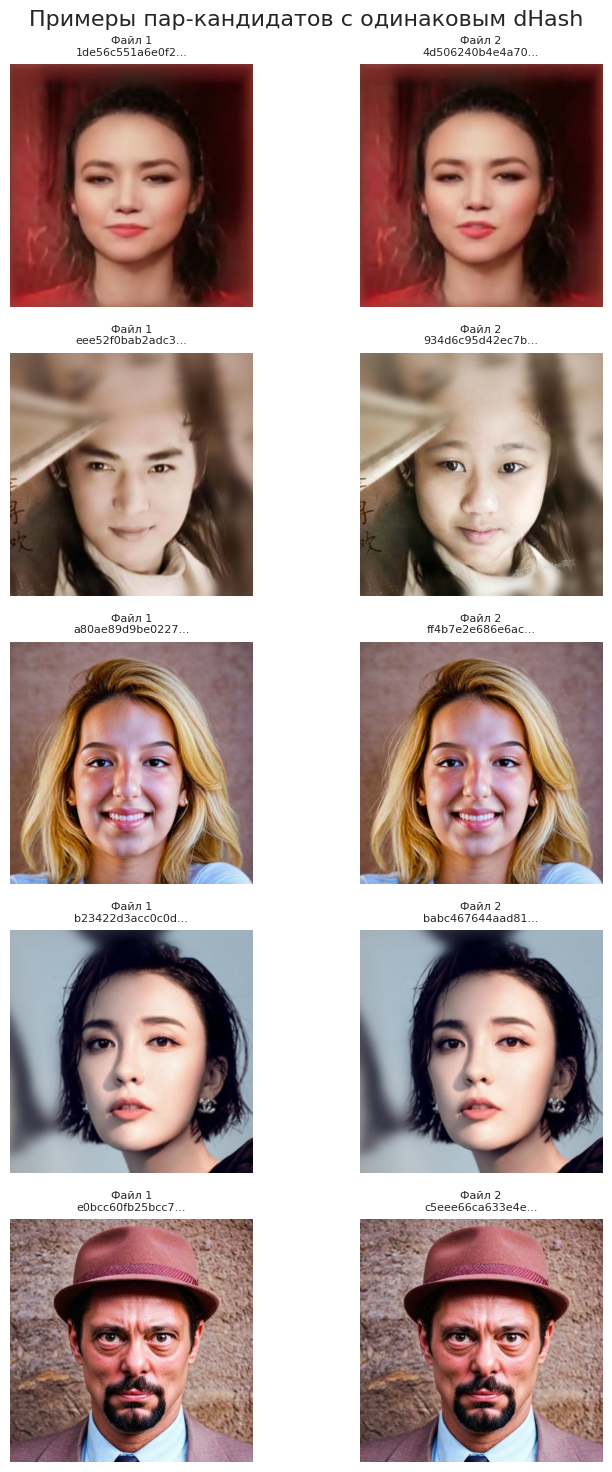

In [7]:
fig, axes = plt.subplots(5, 2, figsize=(8, 15))
fig.suptitle('Примеры пар-кандидатов с одинаковым dHash', fontsize=16)

count = 0
for h, names in exact_duplicates.items():
    if count >= 5: 
        break
    
    img1_name = names[0]
    img2_name = names[1]
    
    img1_path = os.path.join(images_dir, img1_name)
    img1 = cv2.imread(img1_path)
    img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
    
    img2_path = os.path.join(images_dir, img2_name)
    img2 = cv2.imread(img2_path)
    img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)
    
    axes[count, 0].imshow(img1)
    axes[count, 0].set_title(f"Файл 1\n{img1_name[:15]}...", fontsize=8)
    axes[count, 0].axis('off')
    
    axes[count, 1].imshow(img2)
    axes[count, 1].set_title(f"Файл 2\n{img2_name[:15]}...", fontsize=8)
    axes[count, 1].axis('off')
    
    count += 1

plt.tight_layout()
plt.show()

## 6. Бейзлайн (Logistic Regression)

Чтобы понять, насколько проста задача, обучим самую примитивную модель - логистическую регрессию на сырых пикселях. 
*Примечание:* Для скорости мы берем только 2000 картинок и уменьшаем их до 64x64.

In [8]:
X = []
y = []
small_sample = df_sample.head(2000)

print("Загрузка и обработка изображений...")
for index, row in small_sample.iterrows():
    img_path = os.path.join(images_dir, row['filename'])
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    
    if img is not None:
        img = cv2.resize(img, (64, 64)) 
        X.append(img.flatten())        
        y.append(row['label'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print(f"Бейзлайн (Logistic Regression) Accuracy: {acc:.4f}")

Загрузка и обработка изображений...


Бейзлайн (Logistic Regression) Accuracy: 0.6175


In [9]:
real_count = int(class_counts.get(0, 0))
fake_count = int(class_counts.get(1, 0))
candidate_image_count = sum(len(names) for names in exact_duplicates.values())
display(Markdown(
    "## 7. Итоговые выводы по EDA\n\n"
    f"1. Во всём обычном Test **{len(df_full):,}** изображений: "
    f"Real **{real_count:,} ({100 * real_count / len(df_full):.2f}%)**, "
    f"Fake **{fake_count:,} ({100 * fake_count / len(df_full):.2f}%)**.\n\n"
    f"2. Доступно **{len(df_available):,}** исходников; pixel-EDA использует "
    f"**{len(df_sample):,}**. Все контрольные pixel-подвыборки находятся внутри этого пула. Проверка декодирования охватила **{len(check_sample):,}** файлов, "
    f"не прочиталось **{broken_files:,}**. Это результат проверки указанной подвыборки.\n\n"
    f"3. dHash рассчитан для **{len(hashes):,}** из **{len(dedup_sample):,}** выбранных файлов. "
    f"Найдено **{len(exact_duplicates):,}** групп кандидатов; в них "
    f"**{candidate_image_count:,}** изображений "
    f"(**{100 * candidate_image_count / len(dedup_sample):.2f}%** подвыборки). "
    "Совпадение dHash не подтверждает тождество пикселей или точную копию.\n\n"
    f"4. Logistic Regression использует **{len(X):,}** прочитанных изображений 64x64: "
    f"**{len(X_train):,}** для обучения и **{len(X_test):,}** для внутренней проверки. "
    f"Accuracy = **{acc:.4f}**. Это случайный split этой небольшой подвыборки обычного Test; "
    "кандидаты dHash перед этим baseline не удалялись.\n\n"
    "Типы генераторов и манипуляций нельзя восстановить из бинарного файла меток. "
    "Визуальные примеры сами по себе не подтверждают конкретный метод генерации."
))

## 7. Итоговые выводы по EDA

1. Во всём обычном Test **181,947** изображений: Real **77,602 (42.65%)**, Fake **104,345 (57.35%)**.

2. Доступно **181,947** исходников; pixel-EDA использует **20,000**. Все контрольные pixel-подвыборки находятся внутри этого пула. Проверка декодирования охватила **10,000** файлов, не прочиталось **0**. Это результат проверки указанной подвыборки.

3. dHash рассчитан для **5,000** из **5,000** выбранных файлов. Найдено **38** групп кандидатов; в них **80** изображений (**1.60%** подвыборки). Совпадение dHash не подтверждает тождество пикселей или точную копию.

4. Logistic Regression использует **2,000** прочитанных изображений 64x64: **1,600** для обучения и **400** для внутренней проверки. Accuracy = **0.6175**. Это случайный split этой небольшой подвыборки обычного Test; кандидаты dHash перед этим baseline не удалялись.

Типы генераторов и манипуляций нельзя восстановить из бинарного файла меток. Визуальные примеры сами по себе не подтверждают конкретный метод генерации.